In [37]:
import pandas as pd

train_df = pd.read_csv("/content/DailyDelhiClimateTrain.csv")
test_df = pd.read_csv("/content/DailyDelhiClimateTest.csv")

print(train_df.head())
print(train_df.shape)
print(test_df.shape)

         date   meantemp   humidity  wind_speed  meanpressure
0  2013-01-01  10.000000  84.500000    0.000000   1015.666667
1  2013-01-02   7.400000  92.000000    2.980000   1017.800000
2  2013-01-03   7.166667  87.000000    4.633333   1018.666667
3  2013-01-04   8.666667  71.333333    1.233333   1017.166667
4  2013-01-05   6.000000  86.833333    3.700000   1016.500000
(1462, 5)
(114, 5)


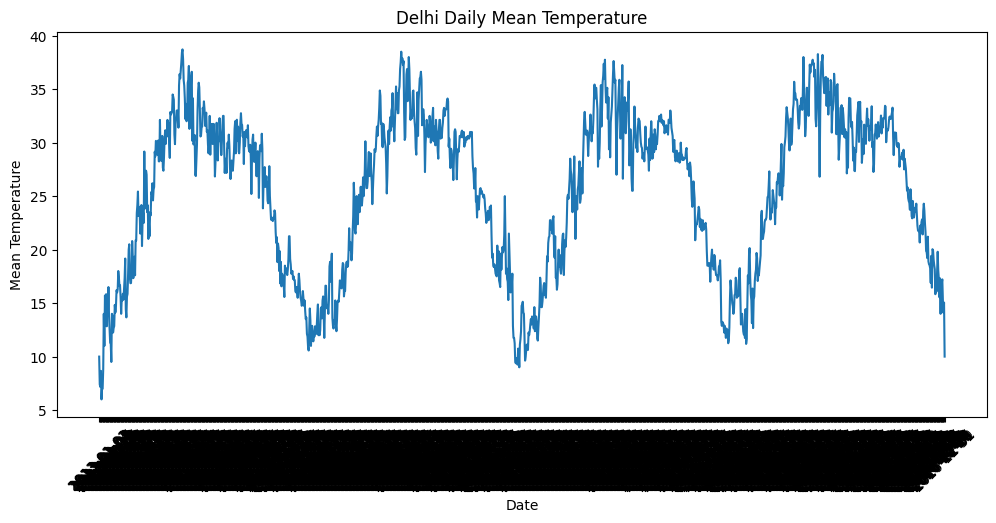

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(train_df["date"], train_df["meantemp"])
plt.xlabel("Date")
plt.ylabel("Mean Temperature")
plt.title("Delhi Daily Mean Temperature")
plt.xticks(rotation=45)
plt.show()

In [39]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

train_temp = train_df[["meantemp"]].values
test_temp = test_df[["meantemp"]].values

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_temp)
test_scaled = scaler.transform(test_temp)

print(train_scaled.shape)
print(test_scaled.shape)

(1462, 1)
(114, 1)


In [40]:
def create_sequences(data, days=7):
    X = []
    y = []

    for i in range(len(data) - days):
        X.append(data[i:i+days])
        y.append(data[i+days])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, 7)
X_test, y_test = create_sequences(test_scaled, 7)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1455, 7, 1)
y_train: (1455, 1)
X_test: (107, 7, 1)
y_test: (107, 1)


In [41]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense

model = Sequential([
    Input(shape=(7, 1)),
    SimpleRNN(50, activation="tanh"),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,901 (15.24 KB)

 Trainable params: 3,901 (15.24 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0084 - mae: 0.0659 - val_loss: 0.0038 - val_mae: 0.0486
Epoch 2/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0032 - mae: 0.0445 - val_loss: 0.0042 - val_mae: 0.0532
Epoch 3/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0031 - mae: 0.0431 - val_loss: 0.0028 - val_mae: 0.0402
Epoch 4/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0029 - mae: 0.0420 - val_loss: 0.0032 - val_mae: 0.0456
Epoch 5/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 - mae: 0.0412 - val_loss: 0.0025 - val_mae: 0.0380
Epoch 6/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031 - mae: 0.0432 - val_loss: 0.0032 - val_mae: 0.0435
Epoch 7/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 - mae: 0.0404 - val_loss: 0.0025 - val_mae: 0.0377
Epoch 8/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0027 - mae: 0.0396 - val_loss: 0.0025 - val_mae: 0.0378
Epoch 9/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0026 - mae:

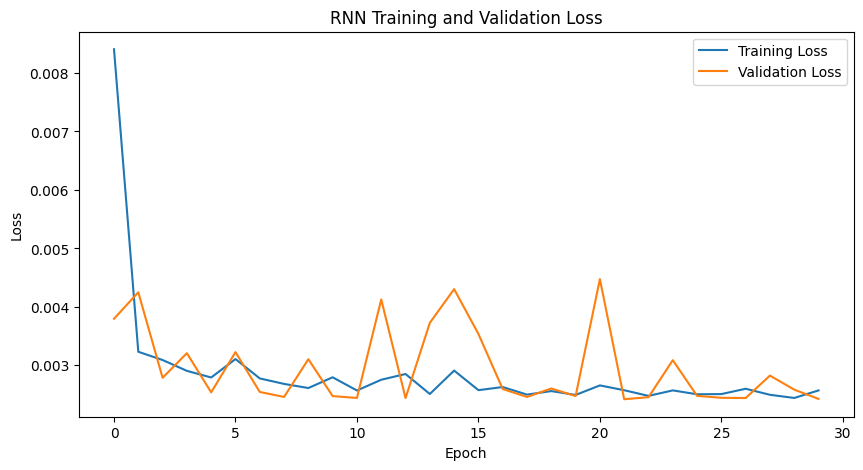

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training and Validation Loss")
plt.legend()
plt.show()

In [44]:
predictions = model.predict(X_test)

predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y_test)

print("Predictions shape:", predictions.shape)
print("Actual shape:", actual.shape)


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 371ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 232ms/step
Predictions shape: (107, 1)
Actual shape: (107, 1)


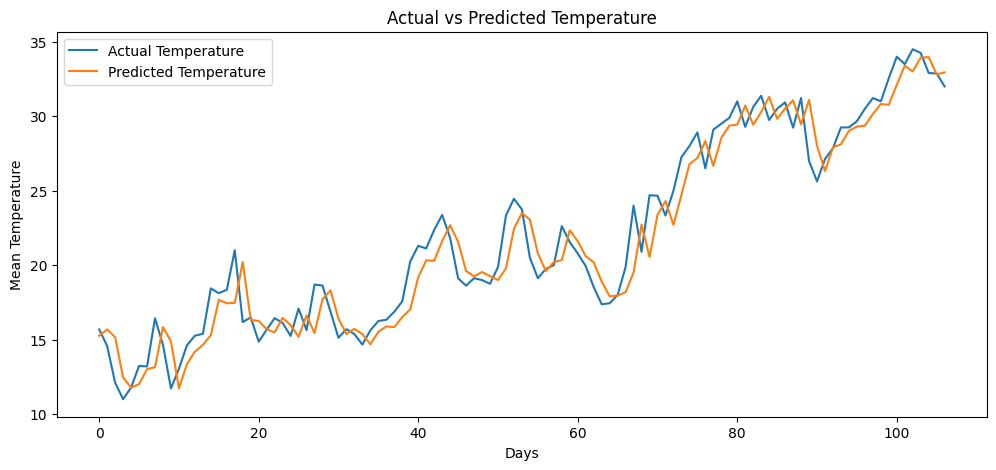

In [45]:
plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual Temperature")
plt.plot(predictions, label="Predicted Temperature")
plt.xlabel("Days")
plt.ylabel("Mean Temperature")
plt.title("Actual vs Predicted Temperature")
plt.legend()
plt.show()

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)

Mean Absolute Error: 1.345979459429443
Root Mean Squared Error: 1.693267370349996


In [47]:
last_7_days = test_scaled[-7:]
last_7_days = last_7_days.reshape(1, 7, 1)

next_day_scaled = model.predict(last_7_days)
next_day_temp = scaler.inverse_transform(next_day_scaled)

print("Predicted temperature for the next day:", round(float(next_day_temp[0][0]), 2), "°C")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Predicted temperature for the next day: 32.36 °C


In [48]:
model.save("/content/delhi_temperature_rnn.keras")
print("Model saved successfully")

Model saved successfully
